# Setup

In [1]:
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
# Questa cella definisce il device una volta per tutte.
# Tutte le altre parti del codice useranno questa variabile.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")


print(f"Current working directory: {os.getcwd()}")

COLAB = False;
if COLAB:
    # Montiamo Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # Definiamo il percorso principale
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    DATASET_PATH = "../../dataset/training/train"

# Se si vuole eseguire tutto solo nel main
EXECUTE_MAIN = False;

Device in uso: cpu
Current working directory: c:\Users\Altair\Documents\GitHub\autoencoder-onboard-segmentation\notebooks\1 - Data Augmentation


## SegmentationDataset

In [2]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    """
    Versione definitiva e semplificata del Dataset.
    Legge le immagini e le maschere che contengono già gli ID di classe.
    """
    def __init__(self, sample_dirs, transform=None):
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self):
        return len(self.sample_dirs)

    def __getitem__(self, idx):
        sample_dir = self.sample_dirs[idx]

        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        # Carichiamo l'immagine RGB e la maschera
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path) # È già in scala di grigi con indici 0-8

        # Convertiamo in array NumPy
        # Normalizziamo l'immagine a [0, 1] per la stabilità del training
        image_np = np.array(image, dtype=np.float32) / 255.0
        # Le maschere contengono ID, quindi usiamo un tipo intero
        mask_np = np.array(mask, dtype=np.int64)

        if self.transform:
            # Qui applicheremo la data augmentation nelle fasi successive
            pass

        # Convertiamo in tensori PyTorch
        # Immagine -> [C, H, W]
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1)
        # Maschera -> [H, W] (la loss CrossEntropy vuole questo formato)
        mask_tensor = torch.from_numpy(mask_np)

        return image_tensor, mask_tensor

In [3]:
import glob
from torch.utils.data import random_split
from typing import Tuple

def split_dataset(data_dir, batch_size) -> Tuple[DataLoader, DataLoader]:
  """
  Funzione per dividere il dataset in training e validation set.
  """

  # 1. Trova tutte le directory dei campioni
  all_sample_dirs = sorted(glob.glob(os.path.join(data_dir, "*")))
  print(f"Trovati {len(all_sample_dirs)} campioni totali.")

  # 2. Dividi le directory in training e validation set
  # Definiamo la dimensione del set di validazione (es. 20%)
  val_percent = 0.20
  n_val = int(len(all_sample_dirs) * val_percent)
  n_train = len(all_sample_dirs) - n_val

  # Usiamo random_split per creare due sotto-liste di percorsi
  # impostiamo un generator per la riproducibilità dello split
  generator = torch.Generator().manual_seed(42)
  train_dirs, val_dirs = random_split(all_sample_dirs, [n_train, n_val], generator=generator)

  print(f"Numero di campioni per training: {len(train_dirs)}")
  print(f"Numero di campioni per validazione: {len(val_dirs)}")

  # 3. Creiamo le istanze dei due Dataset
  train_dataset = SegmentationDataset(sample_dirs=list(train_dirs))
  val_dataset = SegmentationDataset(sample_dirs=list(val_dirs))

  # 4. Creiamo i DataLoader
  # Il DataLoader si occuperà di creare i batch e mescolare i dati
  train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
  val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  return train_loader, val_loader


if not EXECUTE_MAIN:
  train_loader, val_loader = split_dataset(DATASET_PATH, 4)

Trovati 931 campioni totali.
Numero di campioni per training: 745
Numero di campioni per validazione: 186


Forma del batch di immagini: torch.Size([4, 3, 544, 1024])
Forma del batch di maschere: torch.Size([4, 544, 1024])


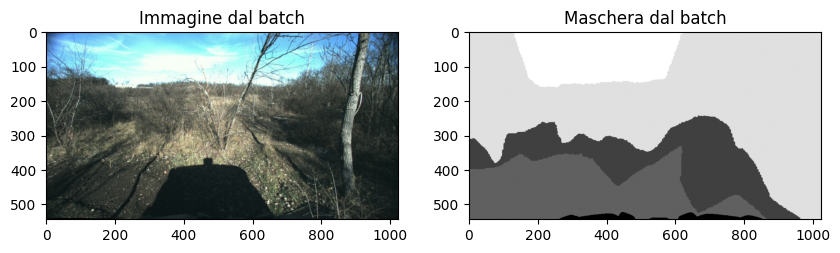

In [4]:
# --- ESEMPIO DI UTILIZZO ---

def segmentationDataset_test(train_loader):
  # Prendiamo un batch dal train_loader per vedere come funziona
  images_batch, masks_batch = next(iter(train_loader))

  print(f"Forma del batch di immagini: {images_batch.shape}") # Dovrebbe essere [batch_size, 3, H, W]
  print(f"Forma del batch di maschere: {masks_batch.shape}") # Dovrebbe essere [batch_size, 1, H, W]

  # Visualizziamo la prima immagine e maschera del batch
  plt.figure(figsize=(10, 5))
  plt.subplot(1, 2, 1)
  plt.imshow(images_batch[0].permute(1, 2, 0)) # Rimetto in formato H, W, C
  plt.title("Immagine dal batch")

  plt.subplot(1, 2, 2)
  plt.imshow(masks_batch[0].squeeze(), cmap='gray')
  plt.title("Maschera dal batch")
  plt.show()



if not EXECUTE_MAIN:
  segmentationDataset_test(train_loader)

# Calcolo della distribuzione del dataset



Trovati 931 campioni totali validi.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:13<00:00,  1.14it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


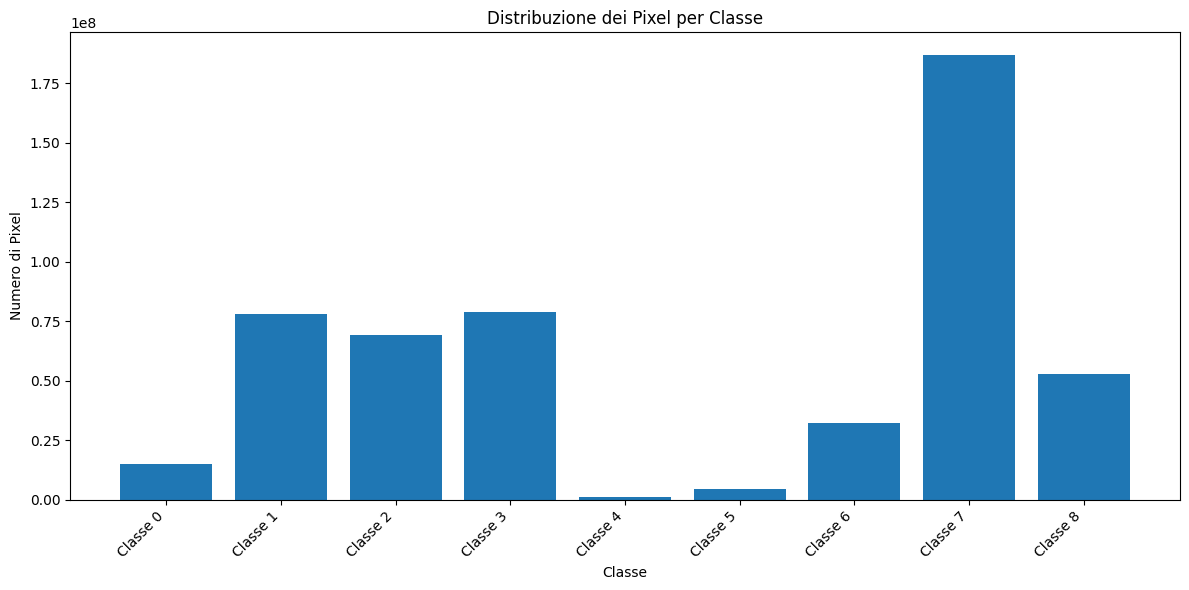

In [5]:
def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  """
  num_classes = 9 # Da 0 a 8

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      class_counts += torch.bincount(mask.flatten(), minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()


def distribution_analysis(full_dataset, class_names):
  # Calcoliamo la distribuzione
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # Stampiamo e visualizziamo i risultati
  total_pixels = distribution.sum()
  print("\nDistribuzione delle classi nel dataset:")
  for i, count in enumerate(distribution):
    percentage = 100 * count.float() / total_pixels
    print(f"- Classe '{class_names[i]}' ({i}): {count} pixel ({percentage:.2f}%)")

  plt.figure(figsize=(12, 6))
  plt.bar(class_names, distribution.numpy())
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()


if not EXECUTE_MAIN:
  # Creiamo un dataset con tutti i campioni ...
  all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
  # ... senza __MACOSX
  all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
  print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

  full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs)

  class_names = []
  for idx in range(9):
    class_names.append(f"Classe {idx}")

  distribution_analysis(full_dataset, class_names)

## Conclusions
---
_it_

Le classi **non sono bilanciate**. La classe 7 rappresenta il **36%**, un valore altissimo.

Questa situazione è **problematica** perché bisogna attuare delle contromisure che spingano il modello a colmare questo gap e diano omogeneità nell'apprendimento, altrimenti si *rischia che la rete ignori completamente le altri classi ed apprenda solo la predominante*.

Per garantire un apprendimento migliore, possiamo utilizzare la data augmentation e cercare una metrica di loss che minimizzi la cross-entropy-loss e attenui lo sbilanciamento delle classi presentie nella realtà di interesse.

L'analisi della distribuzione ci consiglia di non fidarci della sola *accuratezza*. Ci conviene usare il *mean Intersection-over-Union* (IoU), già usata nel contest. Questa metrica ci permette di comprendere quanti pixel riconosce correttamente la rete sia totali che per singola classe. Questo ci consente di poter anche classificare le metriche di loss.

---
_en_:



# Analisi Pre Bilanciamento

--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---

Processing Target: Classe 0


-> Analisi per Classe 0 completata. Trovata in 931 immagini.

Processing Target: Classe 1


-> Analisi per Classe 1 completata. Trovata in 549 immagini.

Processing Target: Classe 2


-> Analisi per Classe 2 completata. Trovata in 642 immagini.

Processing Target: Classe 3


-> Analisi per Classe 3 completata. Trovata in 520 immagini.

Processing Target: Classe 4


-> Analisi per Classe 4 completata. Trovata in 42 immagini.

Processing Target: Classe 5


-> Analisi per Classe 5 completata. Trovata in 164 immagini.

Processing Target: Classe 6


-> Analisi per Classe 6 completata. Trovata in 355 immagini.

Processing Target: Classe 7


-> Analisi per Classe 7 completata. Trovata in 923 immagini.

Processing Target: Classe 8


-> Analisi per Classe 8 completata. Trovata in 844 immagini.


--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---
Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.
             Classe 0  Classe 1  Classe 2  Classe 3  Classe 4  Classe 5  Classe 6  Classe 7  Classe 8
Contesto C0     2.86%    15.04%    13.36%    15.20%     0.18%     0.87%     6.24%    36.06%    10.19%
Contesto C1     2.94%    25.51%    10.84%     3.71%     0.21%     0.83%     6.61%    39.52%     9.82%
Contesto C2     2.42%    11.70%    19.38%    15.67%     0.14%     0.59%     3.30%    36.13%    10.68%
Contesto C3     3.09%     8.97%    11.69%    27.21%     0.09%     1.11%     6.42%    31.08%    10.34%
Contesto C4     4.15%    21.48%     5.81%    12.42%     4.08%     1.96%     6.47%    37.77%     5.86%
Contesto C5     3.60%    21.19%    14.14%    11.21%     0.24%     4.91%     5.46%    29.45%     9.80%
Contesto C6     3.37%    16.17%     6.67%    15.34%     0.24%     

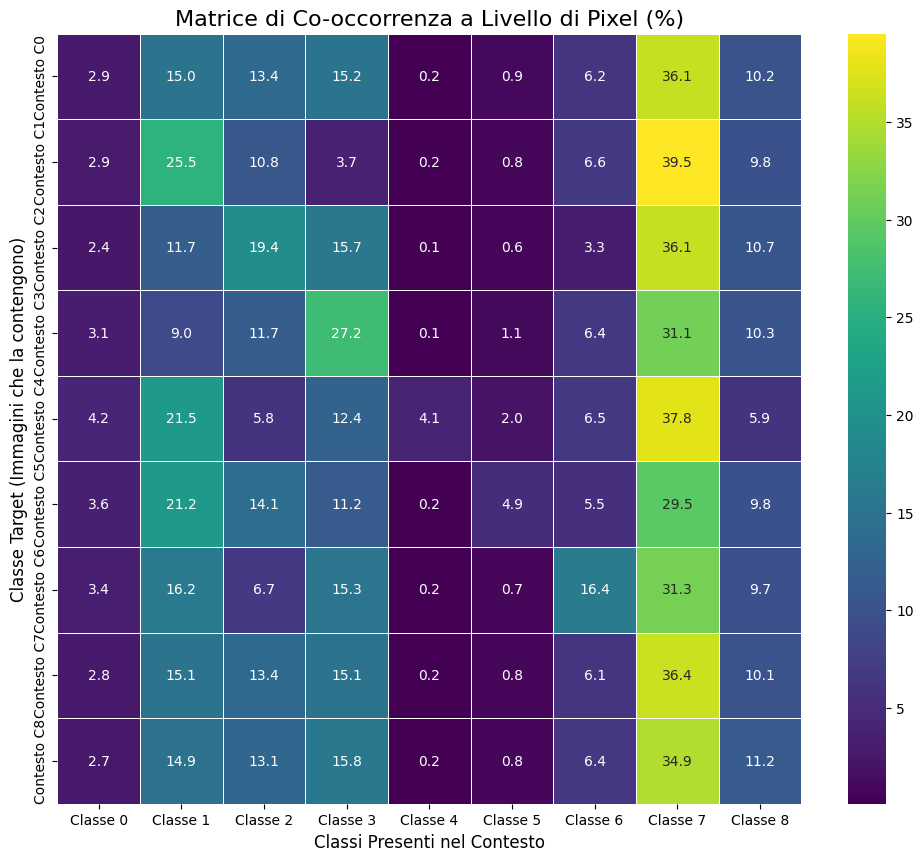

In [6]:
import numpy as np
import os
import glob
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

def analyze_class_context(dataset_path, target_class_id, num_classes=9):
    """
    Analizza il contesto di una classe target.
    (Questa funzione rimane invariata)
    """
    
    total_pixel_counts_in_subset = np.zeros(num_classes, dtype=np.int64)
    num_images_in_subset = 0
    
    all_sample_dirs = sorted(glob.glob(os.path.join(dataset_path, "*")))

    # Il desc della TQDM ora è più generico perché verrà chiamato in un ciclo
    for sample_dir in tqdm(all_sample_dirs, desc=f"Scansione (Target: {target_class_id})", leave=False):
        mask_path = os.path.join(sample_dir, 'labels.png')
        if not os.path.exists(mask_path): continue
        
        mask = np.array(Image.open(mask_path))
        
        unique_classes = np.unique(mask)
        if target_class_id not in unique_classes:
            continue
            
        num_images_in_subset += 1
        
        counts = np.bincount(mask.flatten(), minlength=num_classes)
        total_pixel_counts_in_subset += counts

    if num_images_in_subset == 0:
        return None, 0

    total_pixels_in_subset = total_pixel_counts_in_subset.sum()
    if total_pixels_in_subset == 0:
        return None, num_images_in_subset
        
    avg_distribution = (total_pixel_counts_in_subset / total_pixels_in_subset) * 100
    
    class_names = [f"Classe {i}" for i in range(num_classes)]
    distribution_series = pd.Series(avg_distribution, index=class_names, name=f"Contesto Classe {target_class_id}")
    
    return distribution_series, num_images_in_subset


# --- Esecuzione dell'Analisi Completa ---

SOURCE_DATASET_PATH = "../../dataset/training/train"
NUM_CLASSES = 9

# Ora iteriamo su TUTTE le classi da 0 a 8
all_classes_to_analyze = range(NUM_CLASSES) 
context_results_full = {}

print("--- AVVIO ANALISI DI CONTESTO COMPLETA PER TUTTE LE CLASSI ---")
for class_id in all_classes_to_analyze:
    print(f"\nProcessing Target: Classe {class_id}")
    result, num_images = analyze_class_context(SOURCE_DATASET_PATH, class_id, NUM_CLASSES)
    if result is not None:
        context_results_full[f"Contesto C{class_id}"] = result
        print(f"-> Analisi per Classe {class_id} completata. Trovata in {num_images} immagini.")
    else:
        print(f"-> Classe {class_id} non trovata in nessuna immagine.")

# Creiamo un DataFrame per confrontare facilmente i risultati
if context_results_full:
    comparison_df_full = pd.DataFrame(context_results_full)
    
    # Per una migliore leggibilità, è meglio visualizzare la tabella trasposta
    # righe = classi target, colonne = classi presenti nel contesto
    comparison_df_transposed = comparison_df_full.transpose()
    
    print("\n\n--- TABELLA DI CONFRONTO COMPLETA DEI CONTESTI (Trasposta) ---")
    print("Ogni RIGA mostra la composizione media di un'immagine che contiene la classe target indicata.")
    print(comparison_df_transposed.to_string(float_format="%.2f%%"))

    # Visualizzazione con una Heatmap
    # Una heatmap è molto più efficace di un bar chart con così tanti dati
    plt.figure(figsize=(12, 10))
    # Usiamo la tabella trasposta per avere i target sull'asse Y
    sns.heatmap(
        comparison_df_transposed, 
        annot=True, 
        fmt=".1f", # Mostra una cifra decimale
        cmap='viridis', 
        linewidths=.5
    )
    plt.title('Matrice di Co-occorrenza a Livello di Pixel (%)', fontsize=16)
    plt.xlabel('Classi Presenti nel Contesto', fontsize=12)
    plt.ylabel('Classe Target (Immagini che la contengono)', fontsize=12)
    plt.show()

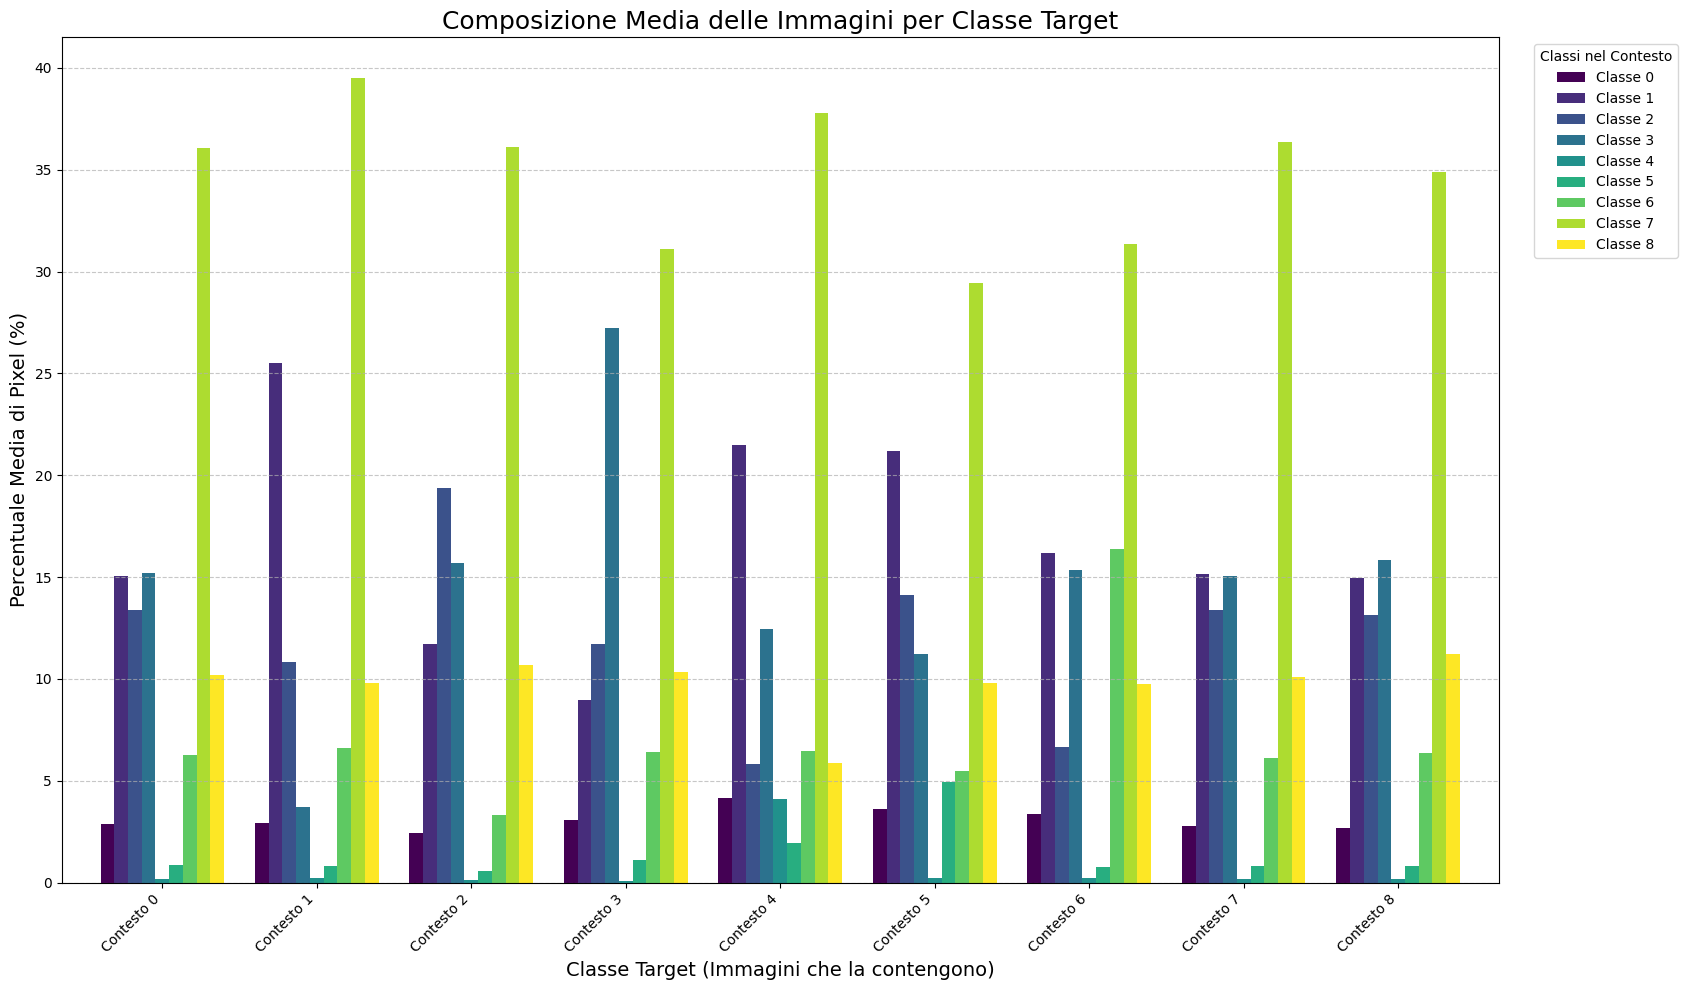

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Assumiamo che 'comparison_df_full' sia il DataFrame che hai generato
# con l'analisi completa. Se non lo hai più in memoria, dovrai rieseguire
# la parte di analisi dello script precedente per ricalcolarlo.

# Esempio di come potrebbe essere il DataFrame (per far funzionare il codice da solo)
# Sostituisci questo con il tuo vero DataFrame se necessario
# data = {'Contesto C0': {'Classe 0': 2.9, 'Classe 1': 15.0, ...}, ...}
# comparison_df_full = pd.DataFrame(data)


# --- GENERAZIONE DEL GRAFICO A BARRE RAGGRUPPATE ---

if 'comparison_df_full' in locals() or 'comparison_df_full' in globals():
    # Trasponiamo il DataFrame per avere le classi target come gruppi sull'asse x
    # e le classi di contesto come barre individuali.
    df_for_plot = comparison_df_full.transpose()

    # Creiamo il grafico
    ax = df_for_plot.plot(
        kind='bar',
        figsize=(20, 10),
        width=0.8,
        colormap='viridis' # Usiamo lo stesso schema di colori della heatmap per coerenza
    )

    # Impostazioni per migliorare la leggibilità
    plt.title('Composizione Media delle Immagini per Classe Target', fontsize=18)
    plt.ylabel('Percentuale Media di Pixel (%)', fontsize=14)
    plt.xlabel('Classe Target (Immagini che la contengono)', fontsize=14)

    # Aggiusta le etichette dell'asse x
    # Estrae i nomi delle classi target (es. 'C0', 'C1') e li formatta
    xtick_labels = [f"Contesto {col.replace('Contesto C', '')}" for col in comparison_df_full.columns]
    ax.set_xticklabels(xtick_labels, rotation=45, ha="right")
    
    plt.legend(title='Classi nel Contesto', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout(rect=[0, 0, 0.85, 1]) # Aggiusta il layout per fare spazio alla leggenda
    
    plt.show()

else:
    print("DataFrame 'comparison_df_full' non trovato. Esegui prima l'analisi completa.")

Perfetto. Questa analisi è la chiave di volta. I dati ci stanno parlando chiaramente.

**La tua intuizione era tragicamente corretta. Abbiamo raggiunto il limite della data augmentation a livello di immagine.**

Analizziamo il grafico e la tabella, perché ci dicono tutto ciò che dobbiamo sapere.

### L'amara Verità rivelata dai Dati

1.  **La Classe 7 è un Parassita Inevitabile:**
    *   **Contesto Classe 4 (blu):** Nelle immagini che contengono la rarissima Classe 4, in media, quasi il **38%** dei pixel appartiene alla Classe 7. È una contaminazione schiacciante.
    *   **Contesto Classe 1 (arancione):** Ancora peggio. Nelle immagini con la Classe 1, la Classe 7 occupa quasi il **40%** dello spazio.
    *   **Contesto Classe 5 (verde):** Anche qui, la Classe 7 è la più presente con quasi il **30%**.
    *   **Conclusione:** Non esistono "partner di augmentation" favorevoli. Le classi rare vivono in simbiosi con il loro "predatore" dominante, la Classe 7. Qualsiasi tentativo di aumentare le classi 4 o 1 aumenterà inevitabilmente e in modo massiccio anche la Classe 7. È un circolo vizioso da cui non possiamo scappare con questa tecnica.

2.  **La Classe 1 ha un "Doppio Problema"**:
    *   Oltre alla Classe 7, le immagini con la Classe 1 contengono anche una quantità enorme della Classe 1 stessa (25.5%). Questo non è sorprendente, ma conferma che è una classe ben definita quando appare. Il problema è che appare raramente, e sempre in compagnia della 7.

3.  **La Classe 5 ha Partner leggermente Diversi:**
    *   È interessante notare che nel contesto della Classe 5 (verde), la Classe 2 e la Classe 3 sono più presenti rispetto agli altri contesti. Tuttavia, la Classe 7 rimane il "capo" indiscusso anche lì.

4.  **La tua Ipotesi è Confermata al 100%:**
    *   La speranza di trovare immagini "pulite" contenenti classi rare è svanita. La natura stessa del dataset lega indissolubilmente le classi rare a quelle dominanti.

### La Decisione Strategica: Cosa Fare Ora

Questa analisi, sebbene deludente, è incredibilmente preziosa perché ci impedisce di perdere altro tempo inseguendo una soluzione impossibile. Ci dice chiaramente quale strada prendere.

**La strategia di augmentation basata sulle correlazioni è impraticabile.**

Dobbiamo accettare che non possiamo "aggiustare" perfettamente i dati. Dobbiamo invece dare al modello gli strumenti per gestire l'imperfezione.

Ecco il piano d'azione definitivo e logico:

**Fase 1: Preparazione del "Miglior Dataset Possibile"**

1.  **Riesegui lo script di augmentation basato sul deficit di pixel**, quello che ha prodotto il risultato che hai postato prima (quello con la Classe 4 all'1.50%). Quello è il **miglior compromesso che possiamo realisticamente ottenere**. Crea la cartella `train_generated_pixel_balanced` (o un nome simile).
2.  **Crea il dataset combinato finale**: Unisci i percorsi dei file originali (`train`) e di quelli appena generati. Questa sarà la nostra fonte di dati per il training.

**Fase 2: Potenziare il Modello e il Training (spostiamo il focus dai dati al modello)**

Qui è dove vinciamo la battaglia. Se non possiamo rendere i dati perfetti, rendiamo il modello più intelligente.

3.  **Implementa una Loss Ponderata (Weighted Cross-Entropy Loss)**: Questa è ora la tecnica **più importante** del nostro arsenale.
    *   Calcola la distribuzione di pixel del nostro **dataset combinato finale**.
    *   Calcola i pesi per ogni classe. Una formula comune è l'inverso della frequenza della radice quadrata: `pesi = 1 / sqrt(frequenze)`. Questo smorza un po' i pesi estremi.
    *   Passa questi pesi alla tua `torch.nn.CrossEntropyLoss(weight=tensor_dei_pesi)`.
    *   **Effetto:** Quando il modello calcola la loss, un errore su un pixel della Classe 4 sarà "pesato" molto di più di un errore su un pixel della Classe 7, costringendo il modello a prestare attenzione.

4.  **Usa Metriche di Valutazione Robuste:** Continua a usare il **mean Intersection over Union (mIoU)**. Ma durante la validazione, stampa l'**IoU per ogni singola classe**. Questo ti permetterà di vedere se i pesi nella loss stanno effettivamente aiutando a migliorare le performance sulle classi 4, 1 e 5.

**In sintesi: Abbiamo spremuto i dati fino all'ultima goccia. Ora è il momento di agire a livello di training.** La combinazione di un dataset *ragionevolmente bilanciato* e una *loss ponderata* è l'approccio standard e più efficace per questo tipo di problema nel mondo reale.



---


Perfetto. Questo grafico, anche se denso, è la prova definitiva. La tua domanda "quindi... come vogliamo fare?" è esattamente il punto a cui volevo arrivare. La risposta ora è chiara e supportata da dati inconfutabili.

**Analisi del Grafico (la "Pistola Fumante")**

Guardiamo insieme cosa ci dice questo grafico, focalizzandoci sulla barra verde brillante (Classe 7):

1.  **Guarda il gruppo "Contesto 4"**: Questo gruppo rappresenta le immagini che contengono la nostra classe più rara. All'interno di questo gruppo, la barra più alta in assoluto è quella della **Classe 7**. È più alta persino della barra della Classe 4 stessa! Questo significa che in un'immagine media con la Classe 4, ci sono più pixel della Classe 7 che della Classe 4.

2.  **Guarda il gruppo "Contesto 1"**: La situazione è ancora più estrema. La barra della **Classe 7** svetta su tutte le altre, raggiungendo quasi il 40%. È una dominanza totale.

3.  **Guarda *tutti* gli altri gruppi**: Nota un pattern schiacciante. In **ogni singolo contesto**, dal Contesto 0 al Contesto 8, la barra della **Classe 7** è sempre tra le più alte, se non la più alta in assoluto.

**La Conclusione Inevitabile**

Non c'è via di fuga. La Classe 7 non è solo una classe comune; è il **tessuto connettivo** di questo dataset. È l'ambiente, lo sfondo, il contesto in cui quasi tutto il resto esiste.

**Risposta diretta a "Come vogliamo fare?":**

**Noi, come data scientist, dichiariamo di aver raggiunto il limite massimo di miglioramento ottenibile tramite data augmentation a livello di immagine.**

Insistere ulteriormente sarebbe come cercare di svuotare l'oceano con un secchiello. Ogni tentativo di aggiungere pixel alle classi rare aggiungerà una quantità proporzionalmente enorme di pixel alla Classe 7, vanificando i nostri sforzi.

### Il Piano d'Azione Definitivo (e questa volta è davvero l'ultimo)

Questo è il percorso professionale e corretto da seguire ora. Spostiamo la nostra intelligenza e i nostri sforzi dal pre-processing dei dati al processo di training stesso.

**Fase 1: Preparazione del Dataset "Meno Peggio"**

1.  **Genera il Dataset Bilanciato**: Esegui per l'ultima volta lo script `create_aug_images_pixel_based()`. Questo creerà il nostro dataset di training, che è il miglior compromesso possibile. Chiamiamo la cartella dei dati generati `train_generated_final`.
2.  **Prepara la Lista Completa dei Dati**: Crea la lista di percorsi che combina i file originali (`train`) e quelli in `train_generated_final`. Questo sarà l'input per i tuoi `DataLoader`.

**Fase 2: Attacco su Due Fronti Durante il Training**

Qui è dove applichiamo le tecniche che funzionano quando i dati non sono perfetti.

3.  **Split Stratificato Intelligente**: Usa la funzione `create_multilabel_stratified_split` che hai già. È fondamentale per garantire che la validazione sia onesta e che le poche istanze delle classi rare siano distribuite equamente tra training e validation.

4.  **Loss Ponderata (Weighted Loss) - IL NOSTRO STRUMENTO PIÙ POTENTE**:
    *   **Calcola i pesi**: Sul tuo dataset **combinato e finale**, calcola la distribuzione di pixel. Poi calcola i pesi per ogni classe. Una buona formula è `peso = 1 / log(1.02 + frequenza_percentuale)`. Il log aiuta a non creare pesi troppo esplosivi per le classi iper-rare.
    *   **Applica i pesi**: Crea il tuo tensore di pesi e passalo alla loss:
      ```python
      # Esempio
      weights = torch.tensor([1.2, 3.5, 1.5, ..., 20.0, ...], dtype=torch.float32).to(device)
      criterion = torch.nn.CrossEntropyLoss(weight=weights)
      ```
    *   Questo costringerà il modello a "preoccuparsi" molto di più quando sbaglia una classe rara, compensando lo squilibrio che non siamo riusciti a eliminare.

**Fase 3: Valutazione e Iterazione**

5.  **Monitoraggio per Classe**: Durante l'allenamento, non limitarti a guardare la loss totale. Stampa l'**IoU (Intersection over Union) per ogni singola classe** sul set di validazione alla fine di ogni epoca.
    *   **Criterio di successo**: Stai avendo successo se vedi che l'IoU delle classi 1, 4 e 5, anche se parte basso, **inizia a salire costantemente**. Questo significa che la loss ponderata sta funzionando.

Questo è il piano. È un piano robusto, collaudato e che affronta il problema nel modo giusto, accettando i limiti dei dati e spostando l'intelligenza nel processo di training. Basta augmentation. È ora di allenare un modello.

# Bilanciamento

In [ ]:
import os
import glob
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt


# --- 1. IMPOSTA I PERCORSI DEL DATASET FINALE ---
ORIGINAL_DATA_PATH = "../../dataset/training/train"
# Questa è la cartella creata dalla nostra pipeline integrata finale
FINAL_AUGMENTED_PATH = "../../dataset/training/train_augmented_adaptive"

# Controlla che entrambe le cartelle esistano
if not os.path.isdir(ORIGINAL_DATA_PATH) or not os.path.isdir(FINAL_AUGMENTED_PATH):
    print("ERRORE: Una o entrambe le cartelle del dataset finale non sono state trovate.")
    print(f"Verifica l'esistenza di '{ORIGINAL_DATA_PATH}' e '{FINAL_AUGMENTED_PATH}'.")
else:
    # Prendi i percorsi da entrambe le cartelle
    dirs_original = sorted([d for d in glob.glob(os.path.join(ORIGINAL_DATA_PATH, "*")) if os.path.isdir(d)])
    dirs_generated = sorted([d for d in glob.glob(os.path.join(FINAL_AUGMENTED_PATH, "*")) if os.path.isdir(d)])

    # COMBINA LE LISTE DI PERCORSI PER IL DATASET COMPLETO
    all_final_dirs = dirs_original + dirs_generated
    
    # Filtro di sicurezza
    all_final_dirs = [d for d in all_final_dirs if not os.path.basename(d).startswith('__')]

    print(f"Analisi del dataset di training finale:")
    print(f"- {len(dirs_original)} campioni originali")
    print(f"- {len(dirs_generated)} campioni generati dalla pipeline integrata")
    print(f"-> Totale campioni per il training: {len(all_final_dirs)}")

    class_names = [f"Classe {i}" for i in range(9)]

    # --- 2. FUNZIONE DI CALCOLO (può rimanere la stessa, è già robusta) ---
    
    def calculate_class_distribution_gpu_final(dataset, device, num_classes=9):
        class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)
        # Se riscontri problemi di memoria, puoi ridurre la batch_size
        loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

        for _, masks_batch in tqdm(loader, desc="Analisi distribuzione finale"):
            masks_batch = masks_batch.to(device)
            for i in range(masks_batch.shape[0]):
                mask = masks_batch[i]
                flat_mask = mask.flatten()
                class_counts += torch.bincount(flat_mask, minlength=num_classes)

        return class_counts.cpu()

    # --- 3. ESEGUI L'ANALISI SUL DATASET FINALE ---
    
    # Crea il dataset a partire dai percorsi finali
    final_combined_dataset = SegmentationDataset(sample_dirs=all_final_dirs)
    
    def generate_controlled_augmentation_dataset():
        # --- CONFIGURAZIONE ---
        SOURCE_DATASET_PATH = "../../dataset/training/train"
        TARGET_AUGMENTED_PATH = "../../dataset/training/train_augmented_controlled"
        BACKGROUND_CLASS_ID = 0

        # --- DEFINIZIONE STRATEGIA DI AUGMENTATION CONTROLLATA ---
        # Definiamo quante nuove versioni vogliamo per ogni classe.
        # Diamo più "amore" alle classi più rare.
        AUGMENTATION_PLAN = {
            4: 15,  # La più rara: generiamo 15 nuove versioni per ogni sua immagine originale
            5: 10,  # La seconda più rara: 10 nuove versioni
            1: 7,   # La terza: 7 nuove versioni
            6: 5    # Meno rara ma comunque da aiutare: 5 versioni
        }
        
        # Le classi da neutralizzare possono ancora essere determinate dinamicamente
        initial_counts = analyze_pixel_distribution(SOURCE_DATASET_PATH)
        class_series = pd.Series(initial_counts[1:], index=range(1, 9))
        CLASSES_TO_NEUTRALIZE = set(class_series.nlargest(2).index.tolist())

        if os.path.exists(TARGET_AUGMENTED_PATH):
            shutil.rmtree(TARGET_AUGMENTED_PATH)
        os.makedirs(TARGET_AUGMENTED_PATH)
            
        print("\n--- Piano di Generazione Controllata ---")
        print(f"Classi da neutralizzare (impostare a 0): {CLASSES_TO_NEUTRALIZE}")
        print("Piano di generazione per classe di interesse:", AUGMENTATION_PLAN)
        print("-" * 50)
        
        # Usiamo un set per non processare due volte la stessa immagine originale nello stesso script
        processed_images = set()

        for class_id, num_versions in AUGMENTATION_PLAN.items():
            print(f"\n--- Processo per la Classe {class_id} (generando {num_versions} versioni per immagine) ---")
            
            # Troviamo tutti i candidati per questa classe
            candidates = find_best_candidates(SOURCE_DATASET_PATH, class_id)
            if not candidates:
                print(f"Nessun candidato trovato per la Classe {class_id}.")
                continue
                
            print(f"Trovati {len(candidates)} candidati. Inizio generazione...")
            
            for candidate in tqdm(candidates, desc=f"Generazione C{class_id}"):
                sample_path = candidate['path']
                
                # Se abbiamo già generato versioni da questa immagine per un'altra classe, saltiamo
                if sample_path in processed_images:
                    continue

                base_name = os.path.basename(sample_path)
                image_np = np.array(Image.open(os.path.join(sample_path, 'rgb.jpg')))
                mask_np = np.array(Image.open(os.path.join(sample_path, 'labels.png')))
                
                # Generiamo il numero fisso di versioni
                for i in range(num_versions):
                    # Pulizia logica on-the-fly
                    cleaned_mask_np = mask_np.copy()
                    for class_to_neutralize in CLASSES_TO_NEUTRALIZE:
                        cleaned_mask_np[mask_np == class_to_neutralize] = BACKGROUND_CLASS_ID
                    
                    # Augmentation visiva on-the-fly
                    augs = create_truly_randomized_augs()
                    transformed = augs(image=image_np, mask=cleaned_mask_np)
                    
                    # Salvataggio
                    new_sample_name = f"{base_name}_aug_c{class_id}_{i+1}"
                    dest_dir = os.path.join(TARGET_AUGMENTED_PATH, new_sample_name)
                    os.makedirs(dest_dir, exist_ok=True)
                    Image.fromarray(transformed['image']).save(os.path.join(dest_dir, 'rgb.jpg'))
                    Image.fromarray(transformed['mask']).save(os.path.join(dest_dir, 'labels.png'))
                
                processed_images.add(sample_path)

        print("\n--- GENERAZIONE CONTROLLATA COMPLETATA ---")

# Esegui la pipeline
generate_controlled_augmentation_dataset()

Analisi preliminare della distribuzione dei pixel...


Analisi Distribuzione: 100%|██████████| 931/931 [00:03<00:00, 265.41it/s]



--- Piano di Generazione Adattiva ---
Classi da neutralizzare: {3, 7}

Scouting candidati per la Classe 4...


Scansione per Classe 4: 100%|██████████| 931/931 [00:04<00:00, 225.07it/s]



Scouting candidati per la Classe 5...


...


Scouting candidati per la Classe 6...


Scansione per Classe 6: 100%|██████████| 931/931 [00:06<00:00, 140.45it/s]



Scouting candidati per la Classe 8...


Scansione per Classe 8: 100%|██████████| 931/931 [00:09<00:00, 94.78it/s]
C:\Users\Altair\AppData\Local\Temp\ipykernel_3148\2703629620.py:35: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(p=random.uniform(0.0, 0.5), alpha=120, sigma=120 * 0.08, alpha_affine=120 * 0.05),
C:\Users\Altair\AppData\Local\Temp\ipykernel_3148\2703629620.py:38: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 90.0), p=random.uniform(0.0, 0.5)),
C:\Users\Altair\AppData\Local\Temp\ipykernel_3148\2703629620.py:40: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=50, max_width=50, p=random.uniform(0.0, 0.5))
Bilanciamento Adattivo: 100%|██████████| 500/500 [00:27<00:00, 18.18it/s, target=C4, median=77333003]


Raggiunto limite massimo di generazioni.

--- GENERAZIONE ADATTIVA COMPLETATA ---


In [ ]:
import os
import glob
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt


# --- 1. IMPOSTA I PERCORSI DEL DATASET FINALE ---
ORIGINAL_DATA_PATH = "../../dataset/training/train"
# Questa è la cartella creata dalla nostra pipeline integrata finale
FINAL_AUGMENTED_PATH = "../../dataset/training/train_augmented_adaptive"

# Controlla che entrambe le cartelle esistano
if not os.path.isdir(ORIGINAL_DATA_PATH) or not os.path.isdir(FINAL_AUGMENTED_PATH):
    print("ERRORE: Una o entrambe le cartelle del dataset finale non sono state trovate.")
    print(f"Verifica l'esistenza di '{ORIGINAL_DATA_PATH}' e '{FINAL_AUGMENTED_PATH}'.")
else:
    # Prendi i percorsi da entrambe le cartelle
    dirs_original = sorted([d for d in glob.glob(os.path.join(ORIGINAL_DATA_PATH, "*")) if os.path.isdir(d)])
    dirs_generated = sorted([d for d in glob.glob(os.path.join(FINAL_AUGMENTED_PATH, "*")) if os.path.isdir(d)])

    # COMBINA LE LISTE DI PERCORSI PER IL DATASET COMPLETO
    all_final_dirs = dirs_original + dirs_generated
    
    # Filtro di sicurezza
    all_final_dirs = [d for d in all_final_dirs if not os.path.basename(d).startswith('__')]

    print(f"Analisi del dataset di training finale:")
    print(f"- {len(dirs_original)} campioni originali")
    print(f"- {len(dirs_generated)} campioni generati dalla pipeline integrata")
    print(f"-> Totale campioni per il training: {len(all_final_dirs)}")

    class_names = [f"Classe {i}" for i in range(9)]

    # --- 2. FUNZIONE DI CALCOLO (può rimanere la stessa, è già robusta) ---
    
    def calculate_class_distribution_gpu_final(dataset, device, num_classes=9):
        class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)
        # Se riscontri problemi di memoria, puoi ridurre la batch_size
        loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

        for _, masks_batch in tqdm(loader, desc="Analisi distribuzione finale"):
            masks_batch = masks_batch.to(device)
            for i in range(masks_batch.shape[0]):
                mask = masks_batch[i]
                flat_mask = mask.flatten()
                class_counts += torch.bincount(flat_mask, minlength=num_classes)

        return class_counts.cpu()

    # --- 3. ESEGUI L'ANALISI SUL DATASET FINALE ---
    
    # Crea il dataset a partire dai percorsi finali
    final_combined_dataset = SegmentationDataset(sample_dirs=all_final_dirs)
    
    def final_distribution_analysis(dataset_to_analyze, class_names_list):
        print("\nCalcolo della distribuzione sul set di training finale...")
        distribution = calculate_class_distribution_gpu_final(dataset_to_analyze, device)
        
        # Escludiamo la classe 0 dal calcolo della percentuale per avere una visione
        # più chiara del bilanciamento tra le classi di interesse (1-8)
        total_pixels_of_interest = distribution[1:].sum()
        
        print("\nDistribuzione dei Pixel nel Dataset di Training Finale:")
        for i, count in enumerate(distribution):
            # Calcola la percentuale sul totale complessivo
            percentage_total = 100 * count.float() / distribution.sum()
            # Calcola la percentuale solo sulle classi 1-8
            percentage_interest = 0
            if i > 0 and total_pixels_of_interest > 0:
                percentage_interest = 100 * count.float() / total_pixels_of_interest

            print(f"- Classe '{class_names_list[i]}' ({i}): {count} pixel ({percentage_total:.2f}% del totale, {percentage_interest:.2f}% delle classi 1-8)")

        # Grafico 1: Distribuzione completa (inclusa la classe 0)
        plt.figure(figsize=(18, 7))
        plt.subplot(1, 2, 1)
        plt.bar(class_names_list, distribution.numpy())
        plt.xlabel("Classe")
        plt.ylabel("Numero di Pixel")
        plt.title("Distribuzione Finale Completa dei Pixel")
        plt.xticks(rotation=45, ha="right")
        plt.grid(axis='y', linestyle='--', alpha=0.7)

        # Grafico 2: Distribuzione solo delle classi di interesse (1-8) per vedere meglio il bilanciamento
        plt.subplot(1, 2, 2)
        plt.bar(class_names_list[1:], distribution.numpy()[1:])
        plt.xlabel("Classe")
        plt.ylabel("Numero di Pixel")
        plt.title("Distribuzione Finale (Solo Classi 1-8)")
        plt.xticks(rotation=45, ha="right")
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        
        plt.tight_layout()
        plt.show()

    final_distribution_analysis(final_combined_dataset, class_names)

ERRORE: Una o entrambe le cartelle del dataset finale non sono state trovate.
Verifica l'esistenza di '../../dataset/training/train' e '../../dataset/training/train_augmented_adaptive'.
Analisi preliminare della distribuzione dei pixel...


Analisi Distribuzione: 100%|██████████| 931/931 [00:03<00:00, 253.70it/s]



--- Piano di Generazione Controllata ---
Classi da neutralizzare (impostare a 0): {3, 7}
Piano di generazione per classe di interesse: {4: 15, 5: 10, 1: 7, 6: 5}
--------------------------------------------------

--- Processo per la Classe 4 (generando 15 versioni per immagine) ---

Scouting candidati per la Classe 4...


Scansione per Classe 4: 100%|██████████| 931/931 [00:03<00:00, 235.45it/s]


Trovati 42 candidati. Inizio generazione...


...

Trovati 549 candidati. Inizio generazione...


Generazione C1: 100%|██████████| 549/549 [01:36<00:00,  5.67it/s]



--- Processo per la Classe 6 (generando 5 versioni per immagine) ---

Scouting candidati per la Classe 6...


Scansione per Classe 6: 100%|██████████| 931/931 [00:05<00:00, 161.23it/s]


Trovati 355 candidati. Inizio generazione...
